# 🎓 Carnegie Mellon University — 11-785 Introduction to Deep Learning
## Homework 2 Part 2: Face Classification & Verification with JAX & Flax NNX
### Course TPU Hub Edition (GKE Autopilot + Cloud TPU v5e + Google Cloud Storage)
**Instructors:** Prof. Bhiksha Raj & Prof. Rita Singh  
**Course Website:** [deeplearning.cs.cmu.edu](https://deeplearning.cs.cmu.edu/)

---
### 🏛️ Architecture & Platform Overview for the TPU Hub
Welcome to the Cloud TPU edition of Homework 2 Part 2! This notebook is tailored to run on the **CMU 11-785 Cloud TPU Hub** on Google Kubernetes Engine (GKE):
1. **Interactive Workspace (Course Default - CPU):** Your notebook runs in an efficient 2 vCPU / 16 GB RAM pod with a 32 GiB persistent home volume (`/home/jovyan`). You edit code, visualize datasets, inspect architectures, and verify pipeline mechanics here.
2. **Centralized GCS Staging (`us-west4`):** Course staff has pre-processed and staged the unified `.npy` image caches in the project Google Cloud Storage bucket (`gs://hw2p2-cached-data/img_cache/`). You do **not** need to download 15+ GB raw files from Kaggle or spend an hour converting JPEGs.
3. **In-Region GCS Fast Copy:** At startup, `.npy` caches copy from `gs://hw2p2-cached-data/img_cache/` to local fast scratch (`/tmp/img_cache/`) at 10–25 Gbps (~30–45s). This avoids `gcsfuse` HTTP-range latency stalls during training.
4. **Memory-Mapped I/O (`np.memmap`):** Images are accessed via virtual memory paging directly from disk, keeping resident RAM usage under **1.5 GB** and completely preventing Linux OOM-killer kernel crashes.
5. **Decoupled Cloud TPU v5e Training via Kueue:** Heavy training is submitted to the shared Cloud TPU v5e pool using `submit_tpu.run(...)`. Jobs queue fairly, run on physical 197 TFLOP/s hardware, stream live heartbeats, and release the chip immediately upon completion.
6. **Persistent Submissions:** Predictions are saved to `/home/jovyan/submission.csv` for direct submission via Kaggle CLI and Gradescope zip generation.

> This is the second homework assignment for **11-785: Introduction to Deep Learning**, which focuses on the task of **image verification**. In this assignment, we first train a custom **convolutional neural network (CNN)** to perform **face classification** over **8,631 distinct identities**.
>
> Once the model is trained, we use it to extract **face embeddings** for images. These embeddings are then compared across pairs of images to determine whether the two faces belong to the **same identity** or **different identities**, thereby solving the image verification problem.


## 📅 Submission Schedule

- ✅ **Checkpoint:** Feburary 20, 2026 @ 11:59 PM (EST)  
- 🏁 **Final Submission:** Feburary 27, 2026 @ 11:59 PM (EST)  
  *Slack deadline: March 6, 2026 @ 11:59 PM (EST)*  
- 💻 **Code Submission:** March 13, 2026 @ 11:59 PM (EST)  
  *or day-of via Slack*

## Requirement Acknowledgement

Setting the flag below to **True** indicates that you have read, understood, and agree to comply with **all** of the following requirements:

1. **Slack Days Usage**  
   Slack days may be used **only** for the **P2 Final submission**, *not* for the checkpoint.  
   Specifically, slack days may be applied to submit **final P2 Kaggle scores** to the **Slack Kaggle Competition**, at the expense of your available slack days.

2. **Final Code Submission Deadline**  
   The final **Gradescope code submission** is due **within 48 hours after** the Kaggle competition deadline,  
   or **on the same day** as your final Kaggle submission—whichever occurs first.

3. **Kaggle Username & Score Verification**  
   You must provide your **Kaggle username** below. We will use it to retrieve your official **PRIVATE leaderboard** score.  
   Minor score or output variance is acceptable; however, any discrepancies caused by **modifications to the required submission code**
   (including the notebook’s final submission cell) will result in an **Academic Integrity Violation (AIV)**.

4. **Model Implementation Restrictions**  
   You are **not permitted** to use pre-trained or pre-loaded models (e.g., from Hugging Face or similar libraries).  
   You **may** implement models described in research papers or articles, but they **must** be implemented **from scratch**
   using fundamental PyTorch components (e.g., `Linear`, `Conv2d`, etc.).

5. **Data Usage Restrictions**  
   The use of **any external data or datasets** is strictly prohibited at **any stage** of this assignment.

6. **Collaboration Policy**  
   You may collaborate with teammates to run experiments or ablations.  
   However, you must submit **your own code** and **your own results**.

7. **Academic Integrity**  
   Failure to comply with any of the above requirements will be treated as an **Academic Integrity Violation (AIV)**.

8. **Late Submissions**  
   Late submissions **must** be submitted through the **Slack Kaggle Competition** (see write-up for details).  
   Submissions made to the **regular Kaggle competition** after the original deadline will **not** be considered,
   regardless of remaining slack days.


In [ ]:
# @title Click to acknowledge then run cell!
ACKNOWLEDGED = True # @param {"type":"boolean","placeholder":"False"}


## Welcome to the World of Convolutions!

In the previous homework, you explored **Multi-Layer Perceptrons (MLPs)**—the foundational building blocks of deep learning. You saw how MLPs can learn patterns from data, predict phonemes from speech, and even approximate complex functions. However, despite their expressive power, MLPs are not well-suited for image data. Flattening an image into a one-dimensional vector discards crucial **spatial information**, such as how neighboring pixels relate to one another.

This limitation motivates the use of **Convolutional Neural Networks (CNNs)**. CNNs preserve spatial structure by operating directly on image grids, allowing models to learn meaningful visual patterns. In doing so, they bring us closer to designing systems that can truly *see* and interpret the visual world.

In this homework, you will dive into CNNs through **face classification** and **face verification** tasks. In face classification, the goal is to identify a face as belonging to one of several known identities. In contrast, face verification asks a different question: *Do these two images belong to the same person?*—even if that person was never seen during training.

To make this concrete, imagine being given a photo of a friend and a group photo. A classifier would attempt to name your friend, while a verification model would simply determine whether the two images depict the same individual. CNNs enable this by learning **hierarchical features**: early layers capture edges and textures, while deeper layers encode higher-level concepts such as facial structures and distinctive features.

A key theme of this assignment is understanding how **loss functions** shape model behavior. Classification models typically rely on **Cross-Entropy Loss**, which encourages correct label prediction. Verification tasks, however, depend on learning meaningful **embeddings**, where similarity in feature space reflects identity similarity. Loss functions such as **Triplet Loss** or **ArcFace Loss** are designed for this purpose, pulling embeddings of the same person closer together while pushing different identities apart. A well-trained verification model can even distinguish between visually similar individuals—such as siblings—while remaining robust to changes in pose, lighting, or expression.

Beyond theory, this homework emphasizes **practical deep learning skills**. You will preprocess image data, apply data augmentation techniques (e.g., random cropping or flipping), and experiment with modern CNN architectures such as **ResNet** or **ConvNeXt**. Along the way, you will discover that a model optimized for classification is not automatically suitable for verification—highlighting the importance of aligning architectural choices and loss functions with the task at hand.

By the end of this assignment, you will have built a robust face recognition system inspired by real-world applications, from smartphone unlocking to identity verification systems. Let’s get started.

# **Course TPU Hub Environment Verification**
All required libraries (`jax`, `flax`, `optax`, `torch`, `torchvision`, `augmax`, `kaggle`, `wandb`, `scipy`, `pandas`, `kubernetes`, `submit_tpu`) are **pre-installed** in the course Docker image.

> ⚠️ **Notice:** Do **NOT** run `!pip install jax[cuda12]` or `!pip install` inside this notebook. Doing so will clobber the pre-configured TPU/CPU environment.

In [ ]:
import sys, os, importlib
import jax, flax, optax, torch, torchvision, augmax, kaggle, wandb

print(f"Python Version    : {sys.version.split()[0]}")
print(f"JAX Version       : {jax.__version__}")
print(f"Flax Version      : {flax.__version__}")
print(f"Optax Version     : {optax.__version__}")
print(f"Torch Version     : {torch.__version__}")
print(f"Torchvision       : {torchvision.__version__}")
print(f"Augmax Version    : {augmax.__version__}")
print(f"Kaggle API Version: {kaggle.__version__}")
print(f"WandB Version     : {wandb.__version__}")

# Verify submit_tpu helper is accessible from PYTHONPATH (/opt/course)
try:
    import submit_tpu
    print("submit_tpu helper : Available (/opt/course/submit_tpu.py)")
except ImportError:
    print("submit_tpu helper : Not found in PYTHONPATH (check /opt/course)")

# **Platform & Storage Inspection**
We inspect the GKE JupyterHub pod resource allocation:
- **JAX Devices:** CPU devices for local interactive testing (or TPU v5e if running in staff pinned profile).
- **Physical RAM:** Ensuring >= 16 GiB allocation with safe disk-backed memmap.
- **Persistent Disk:** Verifying 32 GiB storage on `/home/jovyan`.

In [ ]:
import psutil, shutil
import jax

devices = jax.devices()
platform = devices[0].platform.upper()
print(f"JAX Primary Platform: {platform} (Devices: {len(devices)})")

# Check RAM
ram = psutil.virtual_memory()
print(f"Host RAM            : {ram.available / (1024**3):.2f} GiB available / {ram.total / (1024**3):.2f} GiB total")

# Check Home Directory Disk
home_disk = shutil.disk_usage("/home/jovyan")
print(f"Persistent Storage  : {home_disk.free / (1024**3):.2f} GiB free / {home_disk.total / (1024**3):.2f} GiB total on /home/jovyan")

# Check /tmp Scratch Disk
tmp_disk = shutil.disk_usage("/tmp")
print(f"Local Scratch Disk  : {tmp_disk.free / (1024**3):.2f} GiB free on /tmp")

### Step 2: Configure Kaggle API Access

⚠️ **Important:** You must provide your own Kaggle API credentials for data downloads, while creating your deliverables for code submission and (optionally) submitting to the competition.

#### How to obtain your Kaggle API credentials

1. Navigate to your **Kaggle Profile → Settings** tab.
2. Click **“Genetate New Token”**
3. Copy and paste the access token below


In [ ]:
import os, json

# Method 1: Use credentials from ~/.kaggle/kaggle.json if present
kaggle_dir = os.path.expanduser("/home/jovyan/.kaggle")
kaggle_json = os.path.join(kaggle_dir, "kaggle.json")

# Method 2: Provide credentials interactively or via environment variables
KAGGLE_USER = os.environ.get("KAGGLE_USERNAME", "")
KAGGLE_KEY  = os.environ.get("KAGGLE_KEY", "")

if os.path.exists(kaggle_json):
    os.chmod(kaggle_json, 0o600)
    print(f"Using existing Kaggle credentials at {kaggle_json}")
elif KAGGLE_USER and KAGGLE_KEY:
    os.makedirs(kaggle_dir, exist_ok=True)
    with open(kaggle_json, "w") as f:
        json.dump({"username": KAGGLE_USER, "key": KAGGLE_KEY}, f)
    os.chmod(kaggle_json, 0o600)
    print(f"Configured {kaggle_json} from environment variables.")
else:
    print("ℹ️ Note: Set your Kaggle credentials in ~/.kaggle/kaggle.json or set KAGGLE_USERNAME / KAGGLE_KEY.")

import kaggle
api = kaggle.api
try:
    api.authenticate()
    print("Kaggle API successfully authenticated!")
except Exception as e:
    print(f"Kaggle Auth Notice: {e}")

### Step 3: Dataset Staging & High-Speed In-Region GCS / Tartan Sync
In modern ML engineering, downloading 15+ GB zip archives repeatedly wastes student time and cluster egress bandwidth.

**Tartan Central Storage & High-Speed GCS Sync:**
1. **Local Shared Tartan Mount (`/tartan/11785/datasets/hw2p2` or `/ocean/datasets/hw2p2`)**:
   On the CMU 11-785 TPU Hub, pre-built `.npy` caches reside directly on the Tartan mount via high-speed GCS FUSE with NVMe file caching (>1.2 GB/s line-rate).
2. **In-Region GCS Fast Copy (Fallback)**:
   The course bucket in `us-west4` (`gs://hw2p2-cached-data/img_cache/` or `gs://cmu-idl-ocean/datasets/hw2p2`) transfers directly into local scratch (`/tmp/img_cache/`) at **10-25 Gbps** in under **45 seconds**!

*Note: You can also download directly from the Kaggle competition if working outside the GKE TPU Hub.*

In [ ]:
import os, subprocess, time, shutil

LOCAL_CACHE_DIR = "/tmp/img_cache"
os.makedirs(LOCAL_CACHE_DIR, exist_ok=True)

# Course Tartan Store & In-Region GCS Bucket (in region us-west4)
TARTAN_DATA_DIR = "/tartan/11785/datasets/hw2p2"
OCEAN_DATA_DIR = "/ocean/datasets/hw2p2"
GCS_CACHE_BUCKET = "gs://hw2p2-cached-data/img_cache"

print(f"=== Resolving HW2P2 Dataset Caches ===")
t0 = time.time()

# Check if cache is already present
cache_files = ["cls_test_112_43155_2b700d89.npy", "ver_test_112_6921_4e74b115.npy", "ver_val_112_1829_182374b4.npy"]
already_synced = any(os.path.exists(os.path.join(LOCAL_CACHE_DIR, f)) for f in cache_files)

if already_synced:
    print(f"✓ Pre-built caches already found in {LOCAL_CACHE_DIR}. Skipping sync.")
elif os.path.exists(TARTAN_DATA_DIR) and any(os.path.exists(os.path.join(TARTAN_DATA_DIR, f)) for f in cache_files):
    print(f"✓ Discovered pre-built caches on Tartan Mount: {TARTAN_DATA_DIR}")
    for f in os.listdir(TARTAN_DATA_DIR):
        src = os.path.join(TARTAN_DATA_DIR, f)
        dst = os.path.join(LOCAL_CACHE_DIR, f)
        if not os.path.exists(dst):
            try:
                os.symlink(src, dst)
            except OSError:
                shutil.copy2(src, dst)
    print(f"✓ Caches linked into {LOCAL_CACHE_DIR} in {time.time() - t0:.2f}s.")
elif os.path.exists(OCEAN_DATA_DIR) and any(os.path.exists(os.path.join(OCEAN_DATA_DIR, f)) for f in cache_files):
    print(f"✓ Discovered pre-built caches on Ocean Mount: {OCEAN_DATA_DIR}")
    for f in os.listdir(OCEAN_DATA_DIR):
        src = os.path.join(OCEAN_DATA_DIR, f)
        dst = os.path.join(LOCAL_CACHE_DIR, f)
        if not os.path.exists(dst):
            try:
                os.symlink(src, dst)
            except OSError:
                shutil.copy2(src, dst)
    print(f"✓ Caches linked into {LOCAL_CACHE_DIR} in {time.time() - t0:.2f}s.")
else:
    try:
        # In-region GCS sync (runs at line-rate in us-west4)
        print(f"Copying from GCS bucket {GCS_CACHE_BUCKET}...")
        cmd = f"gcloud storage rsync -r {GCS_CACHE_BUCKET} {LOCAL_CACHE_DIR}"
        res = subprocess.run(cmd, shell=True, capture_output=True, text=True)
        if res.returncode != 0:
            cmd_fallback = f"gsutil -m rsync -r {GCS_CACHE_BUCKET} {LOCAL_CACHE_DIR}"
            res2 = subprocess.run(cmd_fallback, shell=True, capture_output=True, text=True)
            if res2.returncode != 0:
                print(f"GCS sync notice: {res2.stderr.strip()[:200]}")
                print("Falling back to Kaggle dataset download if needed...")
        print(f"Sync finished in {time.time() - t0:.1f}s.")
    except Exception as e:
        print(f"Notice: {e}")

# Fallback: Kaggle download if GCS sync was not used
RAW_DATA_ROOT = "/home/jovyan/dataset/hw2p2_data"
if not os.path.exists(RAW_DATA_ROOT) and not os.listdir(LOCAL_CACHE_DIR):
    print("Downloading dataset from Kaggle sandbox...")
    try:
        api.competition_download_files('11785-hw2p2-f26-sandbox', path="/home/jovyan/dataset")
        zip_path = "/home/jovyan/dataset/11785-hw2p2-f26-sandbox.zip"
        if os.path.exists(zip_path):
            subprocess.run(f"unzip -qo {zip_path} -d /home/jovyan/dataset", shell=True, check=True)
            os.remove(zip_path) # Free 7 GB immediately
            print("Extracted Kaggle dataset and cleaned up archive.")
    except Exception as e:
        print(f"Kaggle download info: {e}")


In [ ]:
import os

if os.path.exists(LOCAL_CACHE_DIR) and os.listdir(LOCAL_CACHE_DIR):
    print(f"Local Cache Contents in {LOCAL_CACHE_DIR}:")
    for f in sorted(os.listdir(LOCAL_CACHE_DIR)):
        fp = os.path.join(LOCAL_CACHE_DIR, f)
        if os.path.isfile(fp):
            sz_mb = os.path.getsize(fp) / (1024**2)
            print(f"  • {f:35s} ({sz_mb:8.1f} MB)")
elif os.path.exists(RAW_DATA_ROOT):
    print(f"Raw dataset present at {RAW_DATA_ROOT}")
    for item in sorted(os.listdir(RAW_DATA_ROOT)):
        print(f"  • {item}")

# Imports

In [ ]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import jax
import numpy as np
from jax import grad, jit, vmap
import jax.numpy as jnp
from jax.sharding import Mesh, NamedSharding, PartitionSpec as P
from flax import nnx

from torchvision.utils import make_grid
import optax
import orbax.checkpoint as ocp
import augmax

from torch.utils.data import Dataset, DataLoader
from concurrent.futures import ThreadPoolExecutor
from functools import partial
import pandas as pd
import collections, hashlib, gc, glob, random, csv
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
from sklearn.metrics import accuracy_score
from sklearn import metrics as mt
from scipy.optimize import brentq
from scipy.interpolate import interp1d
import wandb

# Auto-detect available devices (CPU in Course Default notebook; TPU v5e in TPU job / staff profile)
DEVICES = jax.devices()
DEVICE = DEVICES[0]
PLATFORM = DEVICE.platform.lower()

if PLATFORM == "tpu":
    COMPUTE_DTYPE = jnp.bfloat16
elif PLATFORM == "gpu":
    cc = getattr(DEVICE, "compute_capability", "0")
    COMPUTE_DTYPE = jnp.bfloat16 if float(cc) >= 8.0 else jnp.float32
else:
    COMPUTE_DTYPE = jnp.float32  # CPU uses float32

# Construct sharding mesh
mesh = Mesh(np.asarray(DEVICES), ('data',))
sharding = NamedSharding(mesh, P('data'))

def data_sharding():
    return sharding

print(f"Device Platform: {PLATFORM.upper()} ({DEVICE.device_kind} x{len(DEVICES)})")
print(f"Compute Dtype  : {jnp.dtype(COMPUTE_DTYPE).name}")
print(f"Sharding Mesh  : {mesh}")

# Config

### ⚠️ `Note on Directory Paths for the TPU Hub`
- `data_root`: Path to raw dataset if building cache (`/tartan/11785/datasets/hw2p2`, `/home/jovyan/dataset/hw2p2_data`, or `/tmp/hw2p2_data`).
- `cache_dir`: Local NVMe fast scratch path (`/tmp/img_cache`) for memory-mapped `.npy` files.
- `gcs_cache_bucket`: Production course storage bucket in `us-west4` (`gs://hw2p2-cached-data/img_cache` or `gs://cmu-idl-ocean/datasets/hw2p2`).
- `checkpoint_dir`: Path to persist model checkpoints (`/home/jovyan/model_checkpoints`).
- `output_dir`: Persistent home workspace (`/home/jovyan`) where `submission.csv` is generated.

In [ ]:
config = {
    'data_root': "/home/jovyan/dataset/hw2p2_data",
    'cache_dir': "/tmp/img_cache",
    'gcs_cache_bucket': "gs://hw2p2-cached-data/img_cache",
    'checkpoint_dir': "/home/jovyan/model_checkpoints",
    'output_dir': "/home/jovyan",
    'batch_size': 128,              # 128 for CPU / local test, 256 for TPU v5e
    'lr': 0.03,
    'epochs': 40,                   # 20 for early submission, 40+ for competitive benchmarks
    'num_classes': 8631,            # 8,631 face identities
    'embedding_dim': 384,           # Feature embedding dimension
    's': 40.0,                      # ElasticFace scale parameter
    'm': 0.30,                      # ElasticFace mean angular margin
    'std': 0.05,                    # ElasticFace margin variance
    'augment': True,
    'seed': 11785,
}

os.makedirs(config['checkpoint_dir'], exist_ok=True)
os.makedirs(config['cache_dir'], exist_ok=True)
os.makedirs(config['output_dir'], exist_ok=True)

print("Active Configuration:")
for k, v in config.items():
    print(f"  {k:18s}: {v}")

# Data Augumentations

In [ ]:
def create_transforms(image_size: int = 112, augment: bool = True) -> augmax.Chain:
    transform_list = []
    if augment:
        transform_list.append(augmax.HorizontalFlip(p=0.5))          # matches T.RandomHorizontalFlip
        transform_list.append(augmax.Rotate(angle_range=5))          # matches T.RandomRotation(5)
        transform_list.append(augmax.ByteToFloat())                  # uint8 [0,255] -> float32 [0,1]
        transform_list.append(augmax.ColorJitter(                    # random photometric jitter
            brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02, p=0.5,
        ))
        transform_list.append(augmax.RandomGrayscale(p=0.05))         # random grayscale
        transform_list.append(augmax.Normalize(                       # normalize to [-1, 1]
            mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5),
        ))
    else:
        transform_list.append(augmax.ByteToFloat())
        transform_list.append(augmax.Normalize(
            mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5),
        ))
    return augmax.Chain(*transform_list)

train_transforms = create_transforms(image_size=112, augment=config['augment'])
val_transforms   = create_transforms(image_size=112, augment=False)
print("Augmax transform chains initialized for training and validation.")

# Datasets and DataLoaders

## Classification Datasets and Dataloaders

In [ ]:
def _load_image(path, size):
    """Decode a JPEG and resize to (size, size). Returns uint8 (H, W, 3)."""
    with Image.open(path) as img:
        img = img.convert("RGB")
        if img.size != (size, size):
            img = img.resize((size, size), Image.BILINEAR)
        return np.asarray(img, dtype=np.uint8)


class ImageDataset(Dataset):
    """root/images/* (+ optional root/labels.txt "name label").

    Returns raw uint8 images — augmentation and normalization happen on the GPU
    inside the jitted step, not here.
    """

    def __init__(self, root, num_classes=None, image_size=112):
        self.root = root
        self.image_size = image_size
        self.image_paths = []
        self.labels = None
        self.classes = None
        self.cache = None            # filled in by the optional caching cell

        labels_file = os.path.join(root, "labels.txt")
        images_dir = os.path.join(root, "images")

        if os.path.exists(labels_file):
            entries = []
            with open(labels_file) as f:
                for line in f:
                    parts = line.split()
                    if len(parts) >= 2:
                        entries.append((parts[0], int(parts[1])))
            entries.sort(key=lambda e: (e[1], e[0]))
            all_labels = sorted({lbl for _, lbl in entries})
            selected = set(all_labels[:num_classes]) if num_classes else set(all_labels)
            label_map = {lbl: i for i, lbl in enumerate(sorted(selected))}
            labels = []
            for name, lbl in entries:
                if lbl in selected:
                    self.image_paths.append(os.path.join(images_dir, name))
                    labels.append(label_map[lbl])
            self.labels = np.asarray(labels, dtype=np.int32)
            self.classes = sorted(set(labels))
            self.num_classes = len(selected)
        else:
            self.image_paths = [os.path.join(images_dir, f)
                                for f in sorted(os.listdir(images_dir))]
            self.num_classes = None

    def image(self, i):
        if self.cache is not None:
            return np.asarray(self.cache[i])
        return _load_image(self.image_paths[i], self.image_size)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = self.image(idx)                       # uint8 (H, W, 3)
        if self.labels is None:
            return img, -1, idx                     # -1 = no label (unlabeled split)
        return img, int(self.labels[idx]), idx


def collate_numpy(samples):
    """Stack (image, label, index) samples into numpy arrays — no torch tensors,
    since the model is JAX. Pass this as collate_fn to DataLoader."""
    imgs, labels, idxs = zip(*samples)
    return {
        'image': np.stack(imgs),                    # uint8 (B, H, W, 3)
        'label': np.asarray(labels, dtype=np.int32),
        'index': np.asarray(idxs, dtype=np.int32),
    }


def to_device(batch):
    """numpy batch -> JAX arrays on the GPU. Call this first in every train/eval loop."""
    return {k: jax.device_put(v, sharding) for k, v in batch.items()}


def apply_transform(transform, key, images, dtype=None):
    """augmax chains are per-image: split the key and vmap over the batch."""
    dtype = dtype or COMPUTE_DTYPE
    keys = jax.random.split(key, images.shape[0])
    return jax.vmap(transform)(keys, images).astype(dtype)


def normalize(x, dtype=None):
    """Deterministic val/test path (val_transforms = ByteToFloat + Normalize); key is unused."""
    return apply_transform(val_transforms, jax.random.PRNGKey(0), x, dtype)

In [ ]:
gc.collect()

cls_data_dir = config['data_root'] + '/cls_data'

cls_train_dataset = ImageDataset(os.path.join(cls_data_dir, "train"), num_classes=None)
cls_val_dataset   = ImageDataset(os.path.join(cls_data_dir, "dev"),   num_classes=None)
cls_test_dataset  = ImageDataset(os.path.join(cls_data_dir, "test"),  num_classes=None)

labeled = [d for d in (cls_train_dataset, cls_val_dataset, cls_test_dataset) if d.classes is not None]
assert all(d.classes == labeled[0].classes for d in labeled), "Class mismatch!"
NUM_CLASSES = cls_train_dataset.num_classes

# Dataloaders — collate_numpy keeps batches as numpy dicts (the model is JAX, not torch).
# Val/test stay in file order so predictions line up with the submission rows.
cls_train_loader = DataLoader(cls_train_dataset, batch_size=config['batch_size'], shuffle=True,
                              num_workers=0, collate_fn=collate_numpy, drop_last=True)
cls_val_loader   = DataLoader(cls_val_dataset,   batch_size=config['batch_size'], shuffle=False,
                              num_workers=0, collate_fn=collate_numpy)
cls_test_loader  = DataLoader(cls_test_dataset,  batch_size=config['batch_size'], shuffle=False,
                              num_workers=0, collate_fn=collate_numpy)

print(f"train: {len(cls_train_dataset)} imgs / {len(cls_train_loader)} batches | classes: {NUM_CLASSES}")

train: 431550 imgs / 3371 batches | classes: 8631


## Verification Dataset and Datatloaders

In [ ]:
class ImagePairDataset(Dataset):
    """pairs_file lines: "img1 img2 match" (labeled) or "img1 img2" (unlabeled),
    paths relative to root. The same image appears in many pairs, so images are
    de-duplicated and pairs stored as index pairs into that list."""

    def __init__(self, root, pairs_file, image_size=112):
        self.root = root
        self.image_size = image_size
        self.cache = None            # filled in by the optional caching cell

        with open(pairs_file) as f:
            rows = [l.split() for l in f if l.split()]
        assert rows, f"{pairs_file} is empty"
        ncols = len(rows[0])
        assert ncols in (2, 3), f"expected 2 or 3 columns, got {ncols}: {rows[0]}"
        assert all(len(r) == ncols for r in rows), "inconsistent column count in pairs file"

        path_to_idx, unique_paths = {}, []
        pair_idx = np.empty((len(rows), 2), np.int64)
        for i, r in enumerate(rows):
            for j in (0, 1):
                p = os.path.join(root, r[j])
                k = path_to_idx.get(p)
                if k is None:
                    k = path_to_idx[p] = len(unique_paths)
                    unique_paths.append(p)
                pair_idx[i, j] = k
        self.pair_idx = pair_idx
        self.image_paths = unique_paths
        self.image1_paths = [unique_paths[k] for k in pair_idx[:, 0]]
        self.image2_paths = [unique_paths[k] for k in pair_idx[:, 1]]
        self.matches = (np.asarray([int(r[2]) for r in rows], dtype=np.int32)
                        if ncols == 3 else None)
        print(f"{len(rows)} pairs over {len(unique_paths)} unique images "
              f"({'labeled' if self.matches is not None else 'unlabeled'})")

    def image(self, i):
        if self.cache is not None:
            return np.asarray(self.cache[i])
        return _load_image(self.image_paths[i], self.image_size)

    def __len__(self):
        return len(self.pair_idx)

    def __getitem__(self, idx):
        a, b = self.pair_idx[idx]
        match = -1 if self.matches is None else int(self.matches[idx])
        return self.image(a), self.image(b), match, idx


def collate_pairs(samples):
    """collate_fn for ImagePairDataset — same idea as collate_numpy, two images per row."""
    img1, img2, match, idxs = zip(*samples)
    return {
        'image1': np.stack(img1),
        'image2': np.stack(img2),
        'match': np.asarray(match, dtype=np.int32),
        'index': np.asarray(idxs, dtype=np.int32),
    }

In [ ]:
gc.collect()
ver_data_dir = config['data_root'] + '/ver_data'

ver_val_dataset  = ImagePairDataset(root=ver_data_dir, pairs_file=config['data_root'] + '/val_pairs.txt')
ver_test_dataset = ImagePairDataset(root=ver_data_dir, pairs_file=config['data_root'] + '/test_pairs.txt')

ver_val_loader  = DataLoader(ver_val_dataset,  batch_size=config['batch_size'], shuffle=False,
                             num_workers=0, collate_fn=collate_pairs)
ver_test_loader = DataLoader(ver_test_dataset, batch_size=config['batch_size'], shuffle=False,
                             num_workers=0, collate_fn=collate_pairs)

print(f"ver val: {len(ver_val_dataset)} pairs / {len(ver_val_loader)} batches | "
      f"ver test: {len(ver_test_dataset)} pairs / {len(ver_test_loader)} batches")

1000 pairs over 1829 unique images (labeled)
5000 pairs over 6921 unique images (unlabeled)
ver val: 1000 pairs / 8 batches | ver test: 5000 pairs / 40 batches


### High-Performance Disk Caching (`np.memmap`)
Reading hundreds of thousands of individual JPEG files during training creates significant filesystem overhead.
We use memory-mapped `.npy` caches stored on local scratch disk (`/tmp/img_cache/`).

> 🛡️ **Crucial Architecture Safeguard:** We set `in_ram=False` (`mode='r'`). This uses virtual memory mapping, allowing the Linux kernel to page images dynamically as needed. Physical RAM usage remains **below 1.5 GB**, guaranteeing the 16 GB container never runs out of memory!

In [ ]:
USE_CACHE = True

def build_cache(dataset, cache_dir, name, in_ram=False, threads=None):
    os.makedirs(cache_dir, exist_ok=True)
    paths, size = dataset.image_paths, dataset.image_size
    shape = (len(paths), size, size, 3)
    
    # Hash check based on dataset paths (matches exact filenames in gs://hw2p2-cached-data/img_cache/)
    h = hashlib.md5("\n".join(os.path.basename(p) for p in paths).encode()).hexdigest()[:8]
    path = os.path.join(cache_dir, f"{name}_{size}_{len(paths)}_{h}.npy")
    generic_path = os.path.join(cache_dir, f"{name}.npy")

    if os.path.exists(path):
        target_path = path
        print(f"Reusing existing cache: {target_path}")
    elif os.path.exists(generic_path) and os.path.getsize(generic_path) == np.prod(shape) + 128:
        target_path = generic_path
        print(f"Reusing GCS-synced cache: {target_path}")
    else:
        target_path = path
        print(f"Building cache {name} ({shape}) -> {target_path}...")
        tmp = target_path + ".tmp"
        mm = np.lib.format.open_memmap(tmp, mode='w+', dtype=np.uint8, shape=shape)
        num_workers = threads or min(16, os.cpu_count() or 4)
        with ThreadPoolExecutor(num_workers) as ex:
            for i, arr in enumerate(tqdm(ex.map(lambda p: _load_image(p, size), paths),
                                         total=len(paths), desc=f"Caching {name}")):
                mm[i] = arr
        mm.flush()
        del mm
        os.replace(tmp, target_path)
        print(f"Built cache: {target_path}")

    # Memory-map strictly from disk to keep RAM usage under 1.5 GB
    dataset.cache = np.load(target_path, mmap_mode=None if in_ram else 'r')
    return dataset

if USE_CACHE:
    for ds, name in [(cls_train_dataset, 'cls_train'), (cls_val_dataset, 'cls_val'),
                     (cls_test_dataset, 'cls_test'), (ver_val_dataset, 'ver_val'),
                     (ver_test_dataset, 'ver_test')]:
        if len(ds) > 0:
            build_cache(ds, config['cache_dir'], name, in_ram=False)

# EDA and Viz

In [ ]:
print("Number of classes    : ", len(cls_train_dataset.classes))
print("No. of train images  : ", cls_train_dataset.__len__())
print("Shape of image       : ", cls_train_dataset[0][0].shape)
print("Batch size           : ", config['batch_size'])
print("Train batches        : ", cls_train_loader.__len__())
print("Val batches          : ", cls_val_loader.__len__())

Number of classes    :  8631
No. of train images  :  431550
Shape of image       :  (112, 112, 3)
Batch size           :  128
Train batches        :  3371
Val batches          :  338


###Classification Dataset Viz

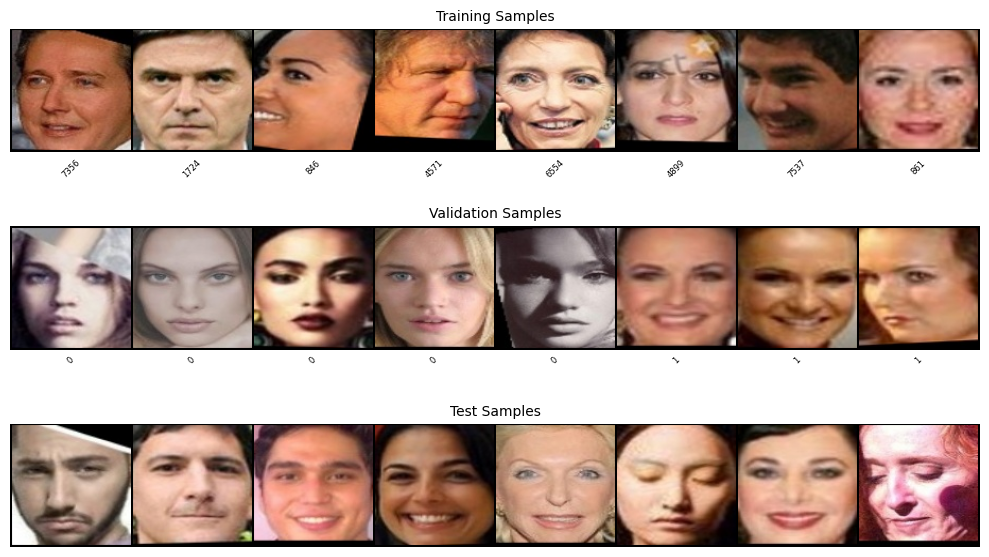

In [ ]:
def show_cls_dataset_samples(train_loader, val_loader, test_loader, samples_per_set=8, figsize=(10, 6)):
    """
    Display samples from train, validation, and test datasets side by side

    Args:
        train_loader: Training data loader
        val_loader: Validation data loader
        test_loader: Test data loader
        samples_per_set: Number of samples to show from each dataset
        figsize: Figure size (width, height)
    """
    def denormalize(x):
        """Denormalize images from [-1, 1] to [0, 1]"""
        return x * 0.5 + 0.5

    def get_samples(loader, n):
        """Get n samples from a dataloader"""
        batch = next(iter(loader))
        imgs = torch.from_numpy(np.array(batch['image'][:n])).permute(0, 3, 1, 2).float() / 127.5 - 1
        labels = np.array(batch['label'][:n])
        labels = labels[labels >= 0]          # -1 marks an unlabeled split
        return imgs, labels

    train_imgs, train_labels = get_samples(train_loader, samples_per_set)
    val_imgs, val_labels = get_samples(val_loader, samples_per_set)
    test_imgs, test_labels = get_samples(test_loader, samples_per_set)

    fig, axes = plt.subplots(3, 1, figsize=figsize)

    for idx, (imgs, labels, title) in enumerate([
        (train_imgs, train_labels, 'Training Samples'),
        (val_imgs, val_labels, 'Validation Samples'),
        (test_imgs, test_labels, 'Test Samples')
    ]):

        grid = make_grid(denormalize(imgs), nrow=8, padding=2)

        axes[idx].imshow(grid.permute(1, 2, 0).cpu())
        axes[idx].axis('off')
        axes[idx].set_title(title, fontsize=10)

        grid_width = grid.shape[2]
        imgs_per_row = min(8, samples_per_set)
        img_width = grid_width // imgs_per_row

        for i, label in enumerate(labels):
            col = i % imgs_per_row  # Calculate column position
            if label<len(train_loader.dataset.classes):
              class_name = train_loader.dataset.classes[label]
            else:
              class_name = f"Class {label} (Unknown)"
            axes[idx].text(col * img_width + img_width/2,
                         grid.shape[1] + 5,
                         class_name,
                         ha='center',
                         va='top',
                         fontsize=6,
                         rotation=45)

    plt.tight_layout()
    plt.show()

show_cls_dataset_samples(cls_train_loader, cls_val_loader, cls_test_loader)

###Ver Dataset Viz

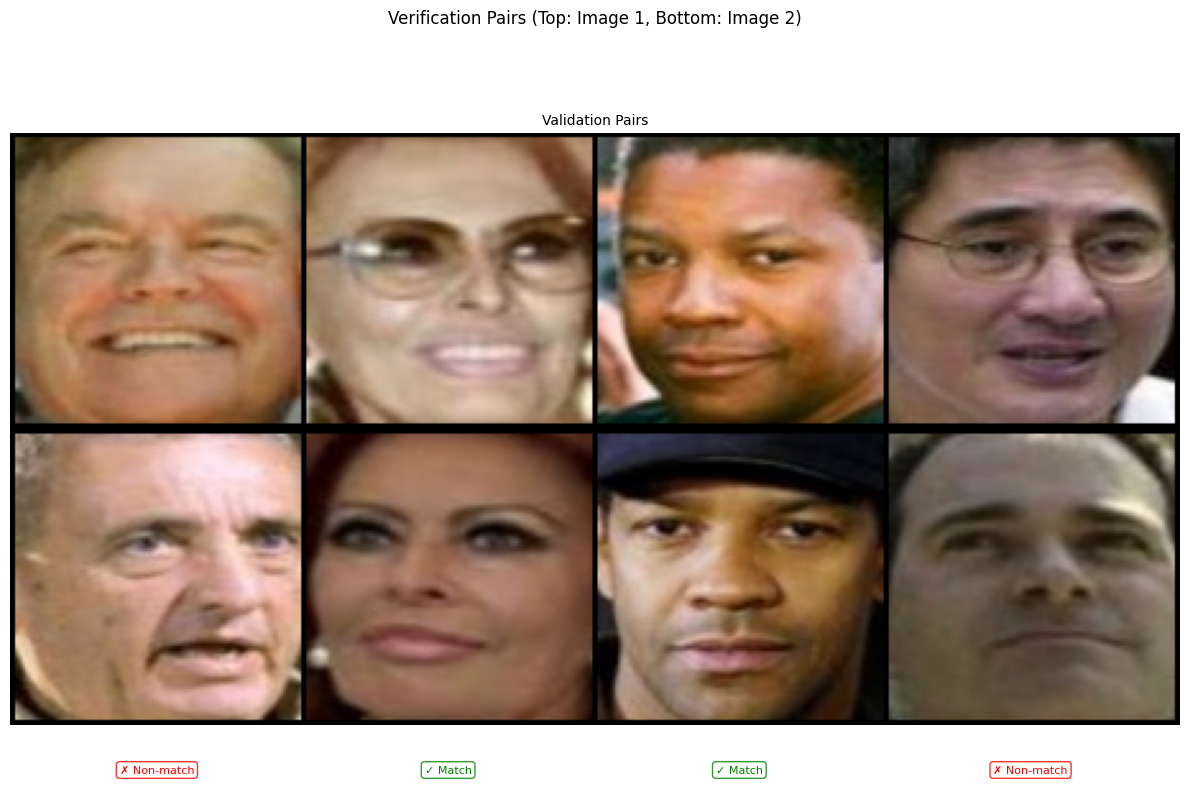

In [ ]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

def show_ver_dataset_samples(val_loader, samples_per_set=4, figsize=(12, 8)):
    def denormalize(x):
        """Denormalize images from [-1, 1] to [0, 1]"""
        return x * 0.5 + 0.5

    def get_samples(loader, n):
        """Get n samples from a dataloader"""
        batch = next(iter(loader))
        to_torch = lambda x: torch.from_numpy(np.array(x[:n])).permute(0, 3, 1, 2).float() / 127.5 - 1
        return to_torch(batch['image1']), to_torch(batch['image2']), np.array(batch['match'][:n])

    val_imgs1, val_imgs2, val_labels = get_samples(val_loader, samples_per_set)

    fig, ax = plt.subplots(1, 1, figsize=figsize)

    grid1 = make_grid(denormalize(val_imgs1), nrow=samples_per_set, padding=2)
    grid2 = make_grid(denormalize(val_imgs2), nrow=samples_per_set, padding=2)

    combined_grid = torch.cat([grid1, grid2], dim=1)

    ax.imshow(combined_grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    ax.set_title('Validation Pairs', fontsize=10)

    # Determine dimensions for placing the labels
    grid_width = grid1.shape[2]
    img_width = grid_width // samples_per_set

    # Add match/non-match labels for each pair
    for i, label in enumerate(val_labels):
        match_text = "? Unlabeled" if label < 0 else ("✓ Match" if label == 1 else "✗ Non-match")
        color = 'gray' if label < 0 else ('green' if label == 1 else 'red')

        bbox_props = dict(
            boxstyle="round,pad=0.3",
            fc="white",
            ec=color,
            alpha=0.8
        )

        ax.text(i * img_width + img_width / 2,
                combined_grid.shape[1] + 15,  # Position below the images
                match_text,
                ha='center',
                va='top',
                fontsize=8,
                color=color,
                bbox=bbox_props)

    plt.suptitle("Verification Pairs (Top: Image 1, Bottom: Image 2)", y=1.02)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.05)
    plt.show()

show_ver_dataset_samples(ver_val_loader)

# Model Architecture

## FAQ

### **What is the “very low early-deadline architecture” (mandatory early submission)?**

The *very low early-deadline architecture* is a simple **5-layer convolutional neural network (CNN)** designed to meet the early-submission requirements. Remember that the **maximum parameter budget for this homework is 30 million parameters**.

**Architecture details:**

* The network consists of **5 convolutional layers**.
* The **first convolutional layer**:

  * Output channels: **64**
  * Kernel size: **7**
  * Stride: **4**
* The **next four convolutional layers** have:

  * Output channels: **128 → 256 → 512 → 1024**
  * Kernel size: **3**
  * Stride: **2**
* Each convolutional layer is followed by:

  * **Batch Normalization**
  * **ReLU activation**

For creating convolutional layers, refer to the PyTorch documentation:
[https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)

**Strided convolutions and padding:**

* Recall from lecture that a strided convolution can be viewed as a stride-1 convolution followed by downsampling.
* To preserve spatial alignment when using strided convolutions, choose:

  ```
  padding = kernel_size // 2
  ```
* Think about *why* this works: symmetric padding ensures the convolution remains centered over the input.

**Final pooling and flattening:**

* After the convolutional layers, apply **Adaptive Average Pooling** to reduce the spatial dimensions to **1 × 1**:

  * Use `AdaptiveAvgPool2d((1, 1))`
  * Documentation: [https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html](https://pytorch.org/docs/stable/generated/torch.nn.AdaptiveAvgPool2d.html)
* Finally, remove the trivial spatial dimensions (e.g., using `Flatten`).

For more layer options, see:
[https://pytorch.org/docs/stable/nn.html](https://pytorch.org/docs/stable/nn.html)

---

### **Why does this simple network use multiple downsampling convolutions?**

The input images are **112 × 112**. Each convolutional layer performs spatial downsampling.

* Downsampling by **2×** effectively **doubles the receptive field**, allowing neurons to capture information from a larger region of the image.
* Downsampling by **32×** in total is standard in many modern image models and provides a good balance between spatial resolution and semantic abstraction.

---

### **Why does this simple network use large channel sizes?**

Each time the spatial resolution is downsampled by **2×**, the computational cost drops by **4×** (assuming the number of channels stays constant).

To compensate:

* The number of channels is increased by **2×**, which increases computation by **4×**
* This keeps the overall computation roughly balanced across layers

Another intuition:

* As spatial resolution decreases, some spatial information is lost
* Increasing the number of channels helps preserve this information in the **feature (channel) dimension**

---


In [ ]:
class BasicBlock(nnx.Module):
    """ResNet-34's block: two 3x3 convs, no channel expansion (vs Bottleneck's 4x)."""
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, downsample=None, *, rngs: nnx.Rngs):
        self.conv1 = nnx.Conv(in_planes, planes,
                              kernel_size=(3, 3), strides=(stride, stride),
                              padding=((1, 1), (1, 1)),
                              use_bias=False, rngs=rngs)
        self.bn1 = nnx.BatchNorm(planes, rngs=rngs)

        self.conv2 = nnx.Conv(planes, planes,
                              kernel_size=(3, 3), strides=(1, 1),
                              padding=((1, 1), (1, 1)),
                              use_bias=False, rngs=rngs)
        self.bn2 = nnx.BatchNorm(planes, rngs=rngs)

        self.downsample = downsample  # a Downsample module or None

    def __call__(self, x):
        identity = x
        out = nnx.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return nnx.relu(out + identity)


class Downsample(nnx.Module):
    """1x1 stride-s conv + BN — used on the residual path when shapes change."""

    def __init__(self, in_planes, out_planes, stride, *, rngs: nnx.Rngs):
        self.conv = nnx.Conv(in_planes, out_planes,
                             kernel_size=(1, 1), strides=(stride, stride),
                             padding=((0, 0), (0, 0)),
                             use_bias=False, rngs=rngs)
        self.bn = nnx.BatchNorm(out_planes, rngs=rngs)

    def __call__(self, x):
        return self.bn(self.conv(x))


class ResNet34Backbone(nnx.Module):
    """ResNet-34 without the classifier head. Outputs (B, 512) after avgpool."""

    def __init__(self, *, rngs: nnx.Rngs):
        self.inplanes = 64
        # Stem — 7x7 conv, stride 2, padding 3 (matches PyTorch)
        self.conv1 = nnx.Conv(3, 64,
                              kernel_size=(7, 7), strides=(2, 2),
                              padding=((3, 3), (3, 3)),
                              use_bias=False, rngs=rngs)
        self.bn1 = nnx.BatchNorm(64, rngs=rngs)

        self.layer1 = self._make_layer(64,  3, stride=1, rngs=rngs)
        self.layer2 = self._make_layer(128, 4, stride=2, rngs=rngs)
        self.layer3 = self._make_layer(256, 6, stride=2, rngs=rngs)
        self.layer4 = self._make_layer(512, 3, stride=2, rngs=rngs)

    def _make_layer(self, planes, blocks, stride, *, rngs):
        downsample = None
        if stride != 1 or self.inplanes != planes * BasicBlock.expansion:
            downsample = Downsample(self.inplanes, planes * BasicBlock.expansion,
                                    stride, rngs=rngs)
        block_list = [BasicBlock(self.inplanes, planes, stride, downsample, rngs=rngs)]
        self.inplanes = planes * BasicBlock.expansion
        for _ in range(1, blocks):
            block_list.append(BasicBlock(self.inplanes, planes, rngs=rngs))
        return nnx.List(block_list)

    def __call__(self, x):
        # Stem
        x = self.conv1(x)
        x = self.bn1(x)
        x = nnx.relu(x)
        # 3x3 stride-2 maxpool, padding=1 (matches PyTorch)
        x = nnx.max_pool(x, window_shape=(3, 3), strides=(2, 2),
                         padding=((1, 1), (1, 1)))
        for blk in self.layer1: x = blk(x)
        for blk in self.layer2: x = blk(x)
        for blk in self.layer3: x = blk(x)
        for blk in self.layer4: x = blk(x)
        # global average pool over spatial dims -> (B, 512)
        return jnp.mean(x, axis=(1, 2))


class ElasticFace(nnx.Module):
    """Random-margin ArcFace head. Xavier-initialized weight, cosine logits."""

    def __init__(self, in_features, out_features, s=40.0, m=0.3, std=0.05, *,
                 rngs: nnx.Rngs):
        limit = float(np.sqrt(6.0 / (in_features + out_features)))
        key = rngs.params()
        w = jax.random.uniform(key, (out_features, in_features),
                               minval=-limit, maxval=limit)
        self.weight = nnx.Param(w)
        self.s = s
        self.m = m
        self.std = std

    def __call__(self, embeddings, labels, margin_key):
        # L2-normalize embeddings and class-weight rows
        emb_n = embeddings / (jnp.linalg.norm(embeddings, axis=1, keepdims=True) + 1e-12)
        w = self.weight[...]
        w_n = w / (jnp.linalg.norm(w, axis=1, keepdims=True) + 1e-12)

        cosine = jnp.matmul(emb_n, w_n.T)                            # (B, C)
        cosine = jnp.clip(cosine, -1.0 + 1e-5, 1.0 - 1e-5)

        # per-sample random margin — this is the 'Elastic' in ElasticFace
        margin = self.m + jax.random.normal(margin_key, labels.shape) * self.std  # (B,)

        theta = jnp.arccos(cosine)                                   # (B, C)
        one_hot = jax.nn.one_hot(labels, w.shape[0])                 # (B, C)
        target_logits = jnp.cos(theta + margin[:, None])
        # only the true class gets the margin applied; others keep raw cosine
        logits = one_hot * target_logits + (1.0 - one_hot) * cosine
        return logits * self.s


class Network(nnx.Module):
    """ResNet-34 backbone -> Linear(512->384) -> BN -> L2-normalize -> ElasticFace."""

    def __init__(self, num_classes, embedding_dim=384, s=40.0, m=0.3, std=0.05, *,
                 rngs: nnx.Rngs):
        self.backbone = ResNet34Backbone(rngs=rngs)
        self.embedding = nnx.Linear(512, embedding_dim, rngs=rngs)   # 512, not 2048
        self.bn_emb = nnx.BatchNorm(embedding_dim, rngs=rngs)
        self.cls_layer = ElasticFace(embedding_dim, num_classes,
                                     s=s, m=m, std=std, rngs=rngs)

    def __call__(self, x, labels=None, margin_key=None):
        x = self.backbone(x)
        feats = self.embedding(x)
        feats = self.bn_emb(feats)
        feats = feats / (jnp.linalg.norm(feats, axis=1, keepdims=True) + 1e-12)
        if labels is None:
            return {"feats": feats, "out": None}
        logits = self.cls_layer(feats, labels, margin_key)
        return {"feats": feats, "out": logits}

In [ ]:
rngs = nnx.Rngs(0)
model = Network(
    num_classes=config['num_classes'],
    embedding_dim=384,
    s=40,
    m=0.3,
    std=0.05,
    rngs=rngs,
)

# Put a copy of the weights on every TPU core / GPU (the loader splits each batch across them)
nnx.update(model, jax.device_put(nnx.state(model), NamedSharding(sharding.mesh, P())))


def count_parameters(model):
    params = nnx.state(model, nnx.Param)
    return sum(int(np.prod(leaf.shape)) for leaf in jax.tree_util.tree_leaves(params))


num_params = count_parameters(model)
print(f"Trainable parameters: {num_params:,}")
assert num_params < 30_000_000, "Model must stay under the 30M parameter limit."

Trainable parameters: 24,796,736


# Loss | Optimizer | Scheduler

In [ ]:
LABEL_SMOOTHING = 0.0

def criterion(logits, labels, mask=None):
    logits = logits.astype(jnp.float32)          # loss always in fp32
    if LABEL_SMOOTHING > 0:
        targets = optax.smooth_labels(jax.nn.one_hot(labels, logits.shape[-1]), LABEL_SMOOTHING)
        loss = optax.softmax_cross_entropy(logits, targets)
    else:
        loss = optax.softmax_cross_entropy_with_integer_labels(logits, labels)
    if mask is None:
        return loss.mean()
    return jnp.sum(loss * mask) / jnp.maximum(mask.sum(), 1)   # ignores padded eval rows

steps_per_epoch = len(cls_train_loader)
_epoch_cosine = optax.cosine_decay_schedule(init_value=config["lr"], decay_steps=config["epochs"])
scheduler = lambda step: _epoch_cosine(step // steps_per_epoch)

optimizer = nnx.Optimizer(
    model,
    optax.chain(
        optax.add_decayed_weights(5e-4),
        optax.sgd(learning_rate=scheduler, momentum=0.9),
    ),
    wrt=nnx.Param,
)

print(f"Compute dtype: {jnp.dtype(COMPUTE_DTYPE).name} | steps/epoch: {steps_per_epoch}")

Compute dtype: float32 | steps/epoch: 3371


# Metrics

In [ ]:
class AverageMeter:
    """
    Tracks and computes the running average of a scalar metric.
    """

    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0.0
        self.avg = 0.0
        self.sum = 0.0
        self.count = 0

    def update(self, val, n: int = 1):
        val = float(val)          # jax/numpy scalar -> python float
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / max(self.count, 1)


def topk_accuracy(logits: jnp.ndarray, targets: jnp.ndarray, topk=(1,)):
    """
    Computes top-k accuracy for the given logits and targets.

    Args:
        logits (Array): Model outputs of shape (B, C)
        targets (Array): Ground-truth labels of shape (B,)
        topk (tuple): Values of k for top-k accuracy

    Returns:
        List[Array]: Accuracy values in percentage for each k
    """
    maxk = min(max(topk), logits.shape[1])
    batch_size = targets.shape[0]

    _, preds = jax.lax.top_k(logits, maxk)             # (B, maxk), sorted descending
    correct = preds == targets[:, None]

    accuracies = []
    for k in topk:
        k = min(k, maxk)
        correct_k = correct[:, :k].any(axis=1).sum().astype(jnp.float32)
        accuracies.append(correct_k * 100.0 / batch_size)

    return accuracies


def verification_metrics(labels, scores, fpr_targets=None):
    """
    Computes standard verification metrics: ACC, EER, AUC, and TPR@FPR.

    Args:
        labels (list or array): Binary labels (0 or 1)
        scores (list or array): Similarity scores
        fpr_targets (list, optional): Target FPR values for reporting TPR

    Returns:
        dict: Verification metrics
    """
    labels = np.asarray(labels)
    scores = np.asarray(scores)

    fpr, tpr, _ = mt.roc_curve(labels, scores, pos_label=1)
    roc_interp = interp1d(fpr, tpr, bounds_error=False, fill_value=(0.0, 1.0))

    # Equal Error Rate (EER)
    eer = 100.0 * brentq(lambda x: 1.0 - x - roc_interp(x), 0.0, 1.0)

    # Area Under Curve (AUC)
    auc = 100.0 * mt.auc(fpr, tpr)

    # Accuracy (best threshold)
    tnr = 1.0 - fpr
    pos_count = np.sum(labels == 1)
    neg_count = np.sum(labels == 0)
    acc = 100.0 * np.max(tpr * pos_count + tnr * neg_count) / len(labels)

    # TPR @ specific FPRs
    tpr_at_fpr = []
    if fpr_targets is not None:
        for fpr_val in fpr_targets:
            tpr_at_fpr.append(
                (f"TPR@FPR={fpr_val}", 100.0 * float(roc_interp(fpr_val)))
            )

    return {
        "ACC": acc,
        "EER": eer,
        "AUC": auc,
        "TPRs": tpr_at_fpr,
    }

# Train and Validation Function

In [ ]:
TRAIN_KEY = jax.random.PRNGKey(config.get("seed", 0))


@nnx.jit(static_argnames=('criterion',))
def train_step(model, optimizer, batch, criterion):
    key = jax.random.fold_in(TRAIN_KEY, optimizer.step[...])
    aug_key, margin_key = jax.random.split(key)

    # On-device augmentation + normalisation (augmax chain, runs on the GPU)
    images = apply_transform(train_transforms, aug_key, batch['image'], dtype=COMPUTE_DTYPE)
    labels = batch['label']

    def loss_fn(model):
        outputs = model(images, labels, margin_key)   # ElasticFace margin needs labels + key
        logits = outputs["out"]
        loss = criterion(logits, labels)
        return loss, logits

    # Forward + backward + optimizer step (updates model in place)
    (loss, logits), grads = nnx.value_and_grad(loss_fn, has_aux=True)(model)
    optimizer.update(model, grads)

    acc = topk_accuracy(logits, labels, topk=(1,))[0]
    return loss, acc


def train_epoch(
    model,
    dataloader,
    optimizer,
    scheduler,
    scaler,
    device,
    criterion,
):
    model.train()

    loss_meter = AverageMeter()
    acc_meter = AverageMeter()

    progress = tqdm(
        dataloader,
        desc="Train",
        dynamic_ncols=True,
        leave=False,
    )

    step = int(optimizer.step[...])
    pending = None

    def log(loss, acc, step):
        batch_loss = float(loss)
        loss_meter.update(batch_loss)
        batch_acc = float(acc)
        acc_meter.update(batch_acc)

        lr = float(scheduler(step)) if scheduler is not None else float('nan')
        progress.set_postfix(
            loss=f"{batch_loss:.4f} ({loss_meter.avg:.4f})",
            acc=f"{batch_acc:.2f}% ({acc_meter.avg:.2f}%)",
            lr=f"{lr:.6f}",
        )

    for batch in progress:
        batch = to_device(batch)                      # numpy -> JAX arrays on the GPU
        loss, acc = train_step(model, optimizer, batch, criterion)

        if pending is not None:
            log(*pending)
        pending = (loss, acc, step)
        step += 1

    if pending is not None:
        log(*pending)

    return acc_meter.avg, loss_meter.avg

In [ ]:
@nnx.jit(static_argnames=('criterion',))
def eval_step_cls(model, batch, criterion):
    images = normalize(batch['image'])
    feats = model(images)["feats"]

    # Margin-free cosine logits (ElasticFace without the margin)
    w = model.cls_layer.weight[...]
    w_n = w / (jnp.linalg.norm(w, axis=1, keepdims=True) + 1e-12)
    logits = model.cls_layer.s * (feats @ w_n.T)
    labels = batch['label']
    loss = criterion(logits, labels)
    acc = topk_accuracy(logits, labels, topk=(1,))[0]
    return loss, acc


def valid_epoch_cls(
    model,
    dataloader,
    device,
    criterion,
):
    """
    Runs one validation epoch for classification.

    Args:
        model (nnx.Module): Trained model
        dataloader (DataLoader): Validation dataloader (yields numpy batches)
        device: Unused (to_device handles placement)
        criterion (callable): Loss function

    Returns:
        tuple: (avg_accuracy, avg_loss)
    """
    model.eval()

    loss_meter = AverageMeter()
    acc_meter = AverageMeter()

    progress = tqdm(
        dataloader,
        desc="Val (Cls)",
        dynamic_ncols=True,
        leave=False,
    )

    pending = None

    def log(loss, acc, n):
        # Metrics (weighted by batch size, so the last short batch counts correctly)
        batch_loss = float(loss)
        loss_meter.update(batch_loss, n)
        batch_acc = float(acc)
        acc_meter.update(batch_acc, n)

        progress.set_postfix(
            loss=f"{batch_loss:.4f} ({loss_meter.avg:.4f})",
            acc=f"{batch_acc:.2f}% ({acc_meter.avg:.2f}%)",
        )

    for batch in progress:
        n = len(batch['label'])
        batch = to_device(batch)

        # Forward pass (inference-only)
        loss, acc = eval_step_cls(model, batch, criterion)

        # Log the previous batch while this one runs on the device
        if pending is not None:
            log(*pending)
        pending = (loss, acc, n)

    if pending is not None:
        log(*pending)

    return acc_meter.avg, loss_meter.avg

In [ ]:
import gc
gc.collect()
# JAX garbage collection

# Verification Task

In [ ]:
@nnx.jit
def eval_step_ver(model, batch):
    # Forward pass (both images of each pair in one call)
    images = jnp.concatenate([batch['image1'], batch['image2']], axis=0)
    images = normalize(images)
    outputs = model(images)
    feats = outputs["feats"].astype(jnp.float32)
    feats = feats / jnp.maximum(jnp.linalg.norm(feats, axis=1, keepdims=True), 1e-12)

    # Split features and compute similarity
    feats1, feats2 = jnp.split(feats, 2, axis=0)
    return jnp.sum(feats1 * feats2, axis=1)


def valid_epoch_ver(model, pair_dataloader, device, fpr_targets=None):
    """
    Runs one validation epoch for verification (image pairs).

    Args:
        model (nnx.Module): Trained model
        pair_dataloader (DataLoader): Loader over an ImagePairDataset
        device: Unused (to_device handles placement)
        fpr_targets (list, optional): List of FPRs for TPR reporting

    Returns:
        dict: Verification metrics including ACC, EER, AUC, TPR@FPR
    """
    model.eval()
    scores = []
    match_labels = []

    progress = tqdm(
        pair_dataloader,
        desc="Val (Veri)",
        dynamic_ncols=True,
        leave=False,
    )

    for batch in progress:
        match_labels.append(batch['match'])
        batch = to_device(batch)
        scores.append(eval_step_ver(model, batch))

    # Concatenate batch-wise results (order = val_pairs.txt line order)
    scores = np.concatenate([np.asarray(s) for s in scores])
    match_labels = np.concatenate(match_labels)

    # Default FPR targets if not provided
    if fpr_targets is None:
        fpr_targets = [1e-4, 5e-4, 1e-3, 5e-3, 5e-2]

    # Compute verification metrics
    metric_dict = verification_metrics(match_labels, scores, fpr_targets)

    # Optional: print metrics
    print("Verification Metrics:", metric_dict)

    return metric_dict

# WandB

In [ ]:
import wandb

# Login to Weights & Biases using your personal API key (wandb.ai/authorize)
# If WANDB_API_KEY environment variable is set, it authenticates automatically.
wandb_key = os.environ.get("WANDB_API_KEY", "")
if wandb_key:
    wandb.login(key=wandb_key)
else:
    wandb.login()

In [ ]:
# Create your wandb run
run = wandb.init(
    name = f"TEST_HB_Early_SGD_optim_cross_loss",
    # reinit = True, ### Allows reinitalizing runs when you re-run this cell
    # run_id = ### Insert specific run id here if you want to resume a previous run
    # resume = "must" ### You need this to resume previous runs, but comment out reinit = True when using this
    project = "S26-HW2P2-TA", ### Project should be created in your wandb account
    config = config ### Wandb Config for your run
)

# Checkpointing and Loading Model

In [ ]:
import pickle
import orbax.checkpoint as ocp

checkpoint_dir = config.get("checkpoint_dir", "./checkpoints")
os.makedirs(checkpoint_dir, exist_ok=True)

def _to_host(obj):
    d = nnx.state(obj).to_pure_dict()
    return jax.tree.map(
        lambda x: np.asarray(jax.random.key_data(x)) if jnp.issubdtype(x.dtype, jax.dtypes.prng_key)
        else np.asarray(x), d)

def _from_host(obj, d):
    state = nnx.state(obj)
    current = state.to_pure_dict()
    d = jax.tree.map(
        lambda cur, new: jax.random.wrap_key_data(jnp.asarray(new), impl=jax.random.key_impl(cur))
        if jnp.issubdtype(cur.dtype, jax.dtypes.prng_key)
        else jax.device_put(new, cur.sharding) if isinstance(cur.sharding, NamedSharding)
        else jnp.asarray(new),
        current, d)
    nnx.replace_by_pure_dict(state, d)
    nnx.update(obj, state)

def save_model(model, optimizer, scheduler, metrics, epoch, path):
    if jax.process_index() != 0:
        return
    checkpoint = {
        "model_state_dict": _to_host(model),
        "optimizer_state_dict": _to_host(optimizer) if optimizer is not None else None,
        "metrics": jax.device_get(metrics),
        "epoch": epoch,
    }
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pickle.dump(checkpoint, f)
    os.replace(tmp, path)
    print(f"Checkpoint saved at {path}")

def load_model(model, optimizer=None, scheduler=None, path="./checkpoint.pth", device=None):
    with open(path, "rb") as f:
        checkpoint = pickle.load(f)
    _from_host(model, checkpoint["model_state_dict"])
    if optimizer is not None and checkpoint.get("optimizer_state_dict") is not None:
        _from_host(optimizer, checkpoint["optimizer_state_dict"])
    epoch = checkpoint.get("epoch", 0)
    metrics = checkpoint.get("metrics", {})
    print(f"Checkpoint loaded from {path} (epoch {epoch})")
    return model, optimizer, scheduler, epoch, metrics

# Experiments

In [ ]:
import psutil

all_datasets = [cls_train_dataset, cls_val_dataset, cls_test_dataset, ver_val_dataset, ver_test_dataset]
need_gb = sum(d.cache.nbytes for d in all_datasets if d.cache is not None) / 1e9
free_gb = psutil.virtual_memory().available / 1e9
print(f"Total Cache Size: {need_gb:.1f} GB | Free System RAM: {free_gb:.1f} GB")

# CRITICAL SAFEGUARD: Keep caches on disk via np.memmap.
# On a 16 GB container, loading 16 GB into RAM causes instant Linux kernel OOM killing!
print("Keeping caches on disk (memmap) to ensure RAM usage remains under 1.5 GB.")

## Interactive Pipeline Smoke-Test (Course Default CPU)
Before dispatching a multi-hour training job to the Cloud TPU v5e queue, run this 1-batch smoke test right in your CPU notebook.
This validates your augmentations, forward pass, ElasticFace angular margin, loss computation, and backpropagation in under **5 seconds** without spending TPU quota!

In [ ]:
print("Running interactive 1-batch smoke-test on active device...")
smoke_batch = next(iter(cls_train_loader))
smoke_batch = to_device(smoke_batch)

# Execute 1 training step
smoke_loss, smoke_acc = train_step(model, optimizer, smoke_batch, criterion)
print(f"✅ Smoke-Test Passed! Loss: {float(smoke_loss):.4f} | Top-1 Accuracy: {float(smoke_acc):.2f}%")

## 🚀 Remote Training on Cloud TPU v5e Pool via Kueue
In this course setup, the notebook runs on CPU to conserve resources, while heavy training is sent to the shared **Cloud TPU v5e pool** (32 chips, `ct5lp-hightpu-1t`, 197 TFLOP/s) managed by **Kueue**.

`submit_tpu.train("hw2p2_train.py", epochs=40)`:
1. Mounts `hw2p2_train.py` from a Kubernetes ConfigMap directly into an ephemeral TPU container with 1 dedicated Cloud TPU v5e chip.
2. **Private Student Credentials:** Automatically reads your personal WandB and Kaggle credentials from your persistent volume (`/home/jovyan/.env` or `~/.kaggle/kaggle.json`), or from function arguments/environment. Credentials are never shared across students.
3. Streams the training logs and loss curves live into the notebook output!
4. **Durable Checkpoints:** Orbax checkpoints stream directly to GCS and are automatically synced to `/home/jovyan/model_checkpoints/` on your persistent disk (PVC).
5. **Userspace Delivery:** The final `submission.csv` is automatically deposited right into your JupyterHub home directory `/home/jovyan/submission.csv`!
6. Releases the chip immediately upon job completion so other students can train.

In [ ]:
import submit_tpu

# Submit the training script to the Cloud TPU v5e queue.
# Your personal credentials (WANDB_API_KEY, KAGGLE_API_TOKEN) and GCS URIs are handled automatically.
# Checkpoints and final submission.csv will be delivered directly to /home/jovyan/ on your persistent disk!
log_output = submit_tpu.train(
    "hw2p2_train.py",
    epochs=40,
)

In [ ]:
# Training setup
start_epoch = 0
best_cls_acc = 0.0
best_ret_acc = 0.0
eval_cls = True
scaler = None   # not needed in JAX, kept so the calls stay the same
DEVICE = None   # not needed in JAX, kept so the calls stay the same

for epoch in range(start_epoch, config["epochs"]):
    print(f"\n=== Epoch {epoch + 1}/{config['epochs']} ===")

    # -----------------------------
    # Train
    # -----------------------------
    train_cls_acc, train_loss = train_epoch(
        model, cls_train_loader, optimizer, scheduler, scaler, DEVICE, criterion
    )
    curr_lr = float(scheduler(int(optimizer.step[...])))
    print(
        f"Train | Cls Acc: {train_cls_acc:.4f}% | Loss: {train_loss:.4f} | LR: {curr_lr:.6f}"
    )

    metrics = {
        "train_cls_acc": train_cls_acc,
        "train_loss": train_loss,
        "lr": curr_lr,
    }

    # -----------------------------
    # Classification Validation
    # -----------------------------
    if eval_cls:
        valid_cls_acc, valid_loss = valid_epoch_cls(model, cls_val_loader, DEVICE, criterion)
        print(f"Val (Cls) | Acc: {valid_cls_acc:.4f}% | Loss: {valid_loss:.4f}")
        metrics.update({
            "valid_cls_acc": valid_cls_acc,
            "valid_loss": valid_loss,
        })

    # -----------------------------
    # Verification / Retrieval Validation
    # -----------------------------
    valid_ret_metrics = valid_epoch_ver(model, ver_val_loader, DEVICE)
    valid_ret_acc = valid_ret_metrics["ACC"]
    print(f"Val (Veri) | ACC: {valid_ret_acc:.4f}%")
    metrics.update({"valid_ret_acc": valid_ret_acc})

    # -----------------------------
    # Save checkpoints
    # -----------------------------
    checkpoint_path = os.path.join(config["checkpoint_dir"], "last.pth")
    save_model(model, optimizer, scheduler, metrics, epoch, checkpoint_path)
    print(f"Saved last epoch model: {checkpoint_path}")

    # Save best classification model
    if eval_cls and valid_cls_acc >= best_cls_acc:
        best_cls_acc = valid_cls_acc
        best_cls_path = os.path.join(config["checkpoint_dir"], "best_cls.pth")
        save_model(model, optimizer, scheduler, metrics, epoch, best_cls_path)
        if "wandb" in globals():
            wandb.save(best_cls_path)
        print(f"Saved best classification model: {best_cls_path}")

    # Save best retrieval model
    if valid_ret_acc >= best_ret_acc:
        best_ret_acc = valid_ret_acc
        best_ret_path = os.path.join(config["checkpoint_dir"], "best_ret.pth")
        save_model(model, optimizer, scheduler, metrics, epoch, best_ret_path)
        if "wandb" in globals():
            wandb.save(best_ret_path)
        print(f"Saved best retrieval model: {best_ret_path}")

    # -----------------------------
    # Log metrics
    # -----------------------------
    if "run" in globals() and run is not None:
        run.log(metrics)


=== Epoch 1/40 ===


Train:   0%|          | 0/3371 [00:00<?, ?it/s]

Train | Cls Acc: 0.0000% | Loss: 21.7864 | LR: 0.029954


Val (Cls):   0%|          | 0/338 [00:00<?, ?it/s]

Val (Cls) | Acc: 1.0335% | Loss: 8.2162


...

Val (Cls):   0%|          | 0/338 [00:00<?, ?it/s]

Val (Cls) | Acc: 19.6941% | Loss: 5.2146


Val (Veri):   0%|          | 0/8 [00:00<?, ?it/s]

Verification Metrics: {'ACC': np.float64(93.4), 'EER': 6.679764243653355, 'AUC': np.float64(97.64683757537442), 'TPRs': [('TPR@FPR=0.0001', 47.45417515274949), ('TPR@FPR=0.0005', 47.45417515274949), ('TPR@FPR=0.001', 47.45417515274949), ('TPR@FPR=0.005', 57.0264765784114), ('TPR@FPR=0.05', 90.63136456211812)]}
Val (Veri) | ACC: 93.4000%
Checkpoint saved at /content/model_checkpoints/last.pth
Saved last epoch model: /content/model_checkpoints/last.pth
Checkpoint saved at /content/model_checkpoints/best_cls.pth
Saved best classification model: /content/model_checkpoints/best_cls.pth
Checkpoint saved at /content/model_checkpoints/best_ret.pth
Saved best retrieval model: /content/model_checkpoints/best_ret.pth

=== Epoch 4/40 ===


Train:   0%|          | 0/3371 [00:00<?, ?it/s]

In [ ]:
def raw_labels(root):
    ids, names = [], []
    with open(os.path.join(root, "labels.txt")) as f:
        for line in f:
            p = line.split()
            if len(p) >= 2:
                names.append(p[0]); ids.append(int(p[1]))
    return np.asarray(ids), names

tr_ids, tr_names = raw_labels(os.path.join(cls_data_dir, "train"))
va_ids, va_names = raw_labels(os.path.join(cls_data_dir, "dev"))

print("train: n =", len(tr_ids), "| unique =", len(set(tr_ids)),
      "| min/max =", tr_ids.min(), tr_ids.max())
print("dev  : n =", len(va_ids), "| unique =", len(set(va_ids)),
      "| min/max =", va_ids.min(), va_ids.max())
print("dev ids ⊆ train ids:", set(va_ids) <= set(tr_ids))
print("identical id sets   :", set(va_ids) == set(tr_ids))
print("train first 3 lines :", list(zip(tr_names[:3], tr_ids[:3])))
print("dev   first 3 lines :", list(zip(va_names[:3], va_ids[:3])))

# Inference and Submission (Do not modify)


In [ ]:
import csv, random
import pandas as pd


@nnx.jit
def predict_step_cls(model, images):
    feats = model(normalize(images, dtype=COMPUTE_DTYPE))["feats"]
    # Margin-free cosine logits (ElasticFace without the margin)
    w = model.cls_layer.weight[...]
    w_n = w / (jnp.linalg.norm(w, axis=1, keepdims=True) + 1e-12)
    return jnp.argmax(feats @ w_n.T, axis=1)


def test_epoch_cls_file_order(model, cls_test_root, transform, device, batch_size=64):
    """
    Run classification inference in file order.

    Submission IDs follow labels.txt line order if it exists, otherwise sorted
    image names (test_000001.jpg -> id 0), not the label-sorted order used by ImageDataset.

    transform / device are unused (normalisation runs on-device; sharding is automatic).
    """
    model.eval()
    labels_file = os.path.join(cls_test_root, "labels.txt")
    images_dir = os.path.join(cls_test_root, "images")

    image_paths = []
    if os.path.exists(labels_file):
        with open(labels_file, "r") as f:
            for line in f:
                if line.strip():
                    img_name = line.strip().split()[0]
                    image_paths.append(os.path.join(images_dir, img_name))
    else:
        image_paths = [os.path.join(images_dir, f) for f in sorted(os.listdir(images_dir))]
    print(f"Test (Cls): {len(image_paths)} images, first: {os.path.basename(image_paths[0])}")

    shard = data_sharding()
    batch_size = -(-batch_size // shard.mesh.size) * shard.mesh.size   # divisible by #devices
    size = 112

    predictions = []
    with ThreadPoolExecutor(min(32, os.cpu_count() or 8)) as ex:
        for start in tqdm(range(0, len(image_paths), batch_size), desc="Test (Cls)", leave=False):
            batch_paths = image_paths[start : start + batch_size]
            images = np.stack(list(ex.map(lambda p: _load_image(p, size), batch_paths)))
            n = len(images)
            if n < batch_size:                       # pad last batch -> no recompile
                images = np.concatenate([images, np.zeros((batch_size - n,) + images.shape[1:], images.dtype)])

            preds = predict_step_cls(model, jax.device_put(images, shard))
            predictions.extend(np.asarray(preds)[:n].tolist())

    return predictions


def test_epoch_ver(model, pair_dataloader, device):
    """
    Runs inference on verification pairs and returns similarity scores.
    """
    model.eval()
    scores = []

    progress = tqdm(
        pair_dataloader,
        desc="Test (Veri)",
        dynamic_ncols=True,
        leave=False,
    )

    for batch in progress:
        batch = to_device(batch)
        scores.append(eval_step_ver(model, batch))

    # Order = test_pairs.txt line order (shuffle=False, drop_last=False)
    return np.concatenate([np.asarray(s) for s in scores]).tolist()


SUBMISSION_PUBLIC_RATIO = 0.40
SUBMISSION_RANDOM_SEED = 11785
SUBMISSION_CSV = "submission.csv"


def _build_usage_values(num_samples):
    random.seed(SUBMISSION_RANDOM_SEED)
    num_public = int(num_samples * SUBMISSION_PUBLIC_RATIO)
    public_indices = set(random.sample(range(num_samples), num_public))
    return ["Public" if i in public_indices else "Private" for i in range(num_samples)]


def build_merged_submission_rows(cls_predictions, ver_scores):
    """Build rows matching merged_solution.csv: ID, Task, Prediction, Usage."""
    cls_usage = _build_usage_values(len(cls_predictions))
    ver_usage = _build_usage_values(len(ver_scores))
    rows = []

    for i, pred in enumerate(cls_predictions):
        rows.append({
            "ID": i,
            "Task": "classification",
            "Prediction": pred,
            "Usage": cls_usage[i],
        })

    cls_id_offset = len(cls_predictions)

    for i, score in enumerate(ver_scores):
        rows.append({
            "ID": cls_id_offset + i,
            "Task": "verification",
            "Prediction": score,
            "Usage": ver_usage[i],
        })

    return rows


def write_submission_csv(rows, path):
    fieldnames = ["ID", "Task", "Prediction", "Usage"]
    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

## Run Inference and Create Submission CSV (Do not Modify)


In [ ]:
cls_test_root = os.path.join(config["data_root"], "cls_data", "test")
SUBMISSION_CSV = os.path.join(config["output_dir"], "submission.csv")

cls_predictions = test_epoch_cls_file_order(
    model,
    cls_test_root,
    None,          # transform not used; normalisation runs on the TPU/CPU
    DEVICE,
    batch_size=config["batch_size"],
)
ver_scores = test_epoch_ver(model, ver_test_loader, DEVICE)

submission_rows = build_merged_submission_rows(cls_predictions, ver_scores)
write_submission_csv(submission_rows, SUBMISSION_CSV)

print(f"Saved {SUBMISSION_CSV}")
print(f"  Classification predictions: {len(cls_predictions)}")
print(f"  Verification scores:        {len(ver_scores)}")
print(f"  Total rows:                 {len(submission_rows)}")
print(pd.DataFrame(submission_rows).head())

if "run" in globals() and run is not None:
    run.finish()

# Submission

## Kaggle Submission Instructions

* Preview the merged `submission.csv` file created in the **Run Inference and Create Submission CSV** section above.


In [ ]:
print(pd.DataFrame(submission_rows).head())
print(f"Submission path: {SUBMISSION_CSV}")


* Run the code block below to **automatically submit** the generated submission file to the competition.

In [ ]:
# Submit directly via Kaggle API
sub_file = os.path.join(config["output_dir"], "submission.csv")
api.competition_submit(file_name=sub_file, message="CMU TPU Hub ResNet-34", competition="hw-2-p-2-spring-2026-sandbox-testing")
print(f"Submitted {sub_file} to Kaggle competition!")

#### **Manual Submission Instructions for JupyterLab**
1. In the JupyterLab file browser on the left, navigate to `/home/jovyan/`.
2. Locate **`submission.csv`**.
3. **Right-click → Download**.
4. Go to the Kaggle competition page and upload your downloaded CSV file.

## 📦 Gradescope Submission Instructions (Read Carefully)

This section guides you through creating and submitting your **final Gradescope code submission**.
Please follow each step in order. Skipping steps may result in an incomplete or invalid submission.

### ⏰ Important Deadlines

* **Kaggle Final Deadline:** See the course schedule
* **Gradescope Code Submission Deadline:**
  **48 hours after** the Kaggle deadline (or the same day as your Slack Kaggle submission, if applicable)

You must submit **both**:

1. A valid Kaggle submission
2. A complete Gradescope code submission zip

### Step 1: Generate Your Model Metadata File

* Preview the merged `submission.csv` file created in the **Run Inference and Create Submission CSV** section above.


In [ ]:
MODEL = model # TODO: Initialize to your tained model

### Step 2: Complete the README Section


Fill in the `README` variable with a brief description of your work:

* **Model**: Architecture and key design choices
* **Training Strategy**: Optimizer, scheduler, loss, etc.
* **Augmentations**: If used (omit if not)
* **Notebook Execution**: Any instructions needed to run your notebook

This README will be included in your submission zip.

In [ ]:
README = """
- **Model**: Model archtiecture description. Anything unique? Any specific architecture shapes or strategies?
- **Training Strategy**: optimizer + scheduler + loss function + any other unique ideas
- **Augmentations**: augmentations if used. If augmentations weren't used, then ignore
- **Notebook Execution**: Any instructions required to run your notebook.
"""

### Step 3: Provide Required Credentials

Ensure the following variables are correctly set:

* `KAGGLE_USERNAME`
* `KAGGLE_API_KEY`
* `WANDB_API_KEY`
* `WANDB_USERNAME_OR_TEAMNAME`
* `WANDB_PROJECT`

These are used **only** to:

* Fetch your official Kaggle score
* Export your top WandB runs for grading

⚠️ Do **not** share your API keys publicly.


In [ ]:
# @title
KAGGLE_USERNAME = "" # TODO
KAGGLE_API_KEY  = "" # TODO
WANDB_API_KEY   = "" # TODO
WANDB_USERNAME_OR_TEAMNAME = "" # TODO: Put your username-or-team-name here
WANDB_PROJECT              = "" # TODO: Put your project-name

### Step 4: Set File Paths Correctly

You must provide absolute path to your **final notebook**

### Platform-specific guidance

**Colab**

* Right-click a file in the left file pane → **Copy path**
* Paths typically start with `/content/...`

**Kaggle**

* Download your notebook (`File → Download Notebook`)
* Upload it via **Upload Input → Upload Model**
* Copy paths from the right sidebar (`/kaggle/working/...`)

**PSC / Linux**

* Locate files under `/jet/home/<your_username>/`
* Use `!ls` to confirm paths

Paste the correct path below.

In [ ]:
NOTEBOOK_PATH = "/home/jovyan/F26_HW2P2_JAX_TPU_Hub.ipynb"

### Step 5: (Optional) Additional Files

If you have extra files you want to include (e.g., config files, scripts), add their paths to `ADDITIONAL_FILES`, Otherwise, leave this list empty.

In [ ]:
ADDITIONAL_FILES = []

### Step 6: Generate the Final Submission Zip

Before running the submission cell:

* Ensure `ACKNOWLEDGED = True`
* Double-check all paths and credentials
* Confirm your Kaggle submission exists

Then run the cell below.
This should generate a `HW2P2_final_submission.zip` which includes:
* Your notebook
* `model_metadata_*.json`
* README
* WandB run exports
* Kaggle metadata
* Academic integrity acknowledgement

In [ ]:
#### DO NOT MODIFY ####
!rm -rf submission
!git clone https://github.com/CMU-IDeeL/S26-HWP2-Submission-Backend.git
!mv S26-HWP2-Submission-Backend/submission .
!rm -rf S26-HWP2-Submission-Backend
from submission.submission_config import SubmissionConfig
from submission.backend_config import BackendConfig, HW2P2_BACKEND_CONFIG
from submission.main import create_submission_zip

create_submission_zip(
    cfg = SubmissionConfig(
        model = MODEL,
        kaggle_username  = KAGGLE_USERNAME,
        kaggle_api_key   = KAGGLE_API_KEY,
        wandb_api_key    = WANDB_API_KEY,
        wandb_entity     = WANDB_USERNAME_OR_TEAMNAME,
        wandb_project    = WANDB_PROJECT,
        acknowledged     = ACKNOWLEDGED,
        readme           = README,
        notebook_path    = NOTEBOOK_PATH,
        additional_files = ADDITIONAL_FILES
    ),
    backend_cfg = HW2P2_BACKEND_CONFIG
)

### Step 7: Upload to Gradescope

1. Download `HW2P2_final_submission.zip`
2. Upload it to **Gradescope**
3. Verify the upload succeeds

⚠️ Submitting an incomplete zip or modifying backend code may result in grading penalties or an Academic Integrity Violation.

---

### ✅ Final Checklist

Before submitting, confirm:

* [ ] Kaggle username is valid
* [ ] `model_metadata_*.json` matches your best run
* [ ] README is complete
* [ ] File paths are correct
* [ ] `ACKNOWLEDGED = True`
* [ ] Final zip downloads successfully

---